In [ ]:
from sklearn.datasets import load_wine
import pandas as pd
import sklearn as sk
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

In [2]:
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

In [3]:
y

0      0
1      0
2      0
3      0
4      0
      ..
173    2
174    2
175    2
176    2
177    2
Name: target, Length: 178, dtype: int64

In [4]:
X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [5]:
print("Размер данных:", X.shape)
print("Количество классов:", y.nunique())

Размер данных: (178, 13)
Количество классов: 3


In [6]:
prizn = [x for x in (X.columns)]
for x in prizn:
    print(x, ":", type(X[x][0]))

alcohol : <class 'numpy.float64'>
malic_acid : <class 'numpy.float64'>
ash : <class 'numpy.float64'>
alcalinity_of_ash : <class 'numpy.float64'>
magnesium : <class 'numpy.float64'>
total_phenols : <class 'numpy.float64'>
flavanoids : <class 'numpy.float64'>
nonflavanoid_phenols : <class 'numpy.float64'>
proanthocyanins : <class 'numpy.float64'>
color_intensity : <class 'numpy.float64'>
hue : <class 'numpy.float64'>
od280/od315_of_diluted_wines : <class 'numpy.float64'>
proline : <class 'numpy.float64'>


Все признаки имеют тип данных float

In [7]:
X.notnull().count()

alcohol                         178
malic_acid                      178
ash                             178
alcalinity_of_ash               178
magnesium                       178
total_phenols                   178
flavanoids                      178
nonflavanoid_phenols            178
proanthocyanins                 178
color_intensity                 178
hue                             178
od280/od315_of_diluted_wines    178
proline                         178
dtype: int64

Пропуски отстутсвуют 

In [8]:
counts = y.value_counts().sort_index()
print(counts)

target
0    59
1    71
2    48
Name: count, dtype: int64


Объектов 1 типа: 59
Объектов 2 типа: 71
Объектов 3 типа: 48

Признаки -> X Целевые переменные -> y

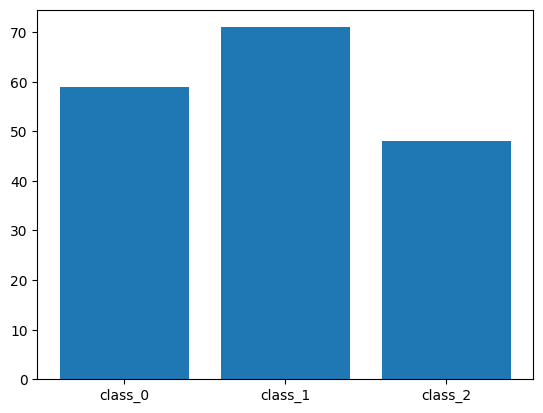

In [9]:
plt.bar(wine.target_names, counts.values)
plt.show()

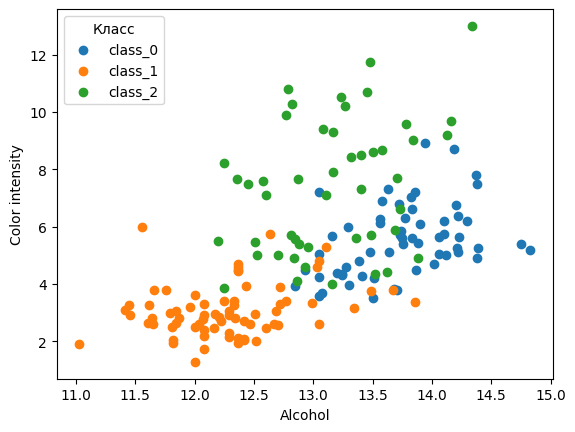

In [10]:
for class_id, class_name in enumerate(wine.target_names):
    mask = y == class_id
    plt.scatter(
        X.loc[mask, "alcohol"],
        X.loc[mask, "color_intensity"],
        label=class_name,
    )

plt.xlabel("Alcohol")
plt.ylabel("Color intensity")
plt.legend(title="Класс")

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [12]:
modelK = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))])
modelT = DecisionTreeClassifier(max_depth=3, random_state=42)

In [13]:
modelK.fit(X_train, y_train)

,steps,"[('scaler', ...), ('knn', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


In [14]:
modelT.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [15]:
predK = modelK.predict(X_test)
predT = modelT.predict(X_test)

In [16]:
accK = accuracy_score(y_test, predK)
accT = accuracy_score(y_test, predT)

In [17]:
print("KNN accuracy:", accK)
print("Decision Tree accuracy:", accT)

KNN accuracy: 0.9722222222222222
Decision Tree accuracy: 0.9444444444444444


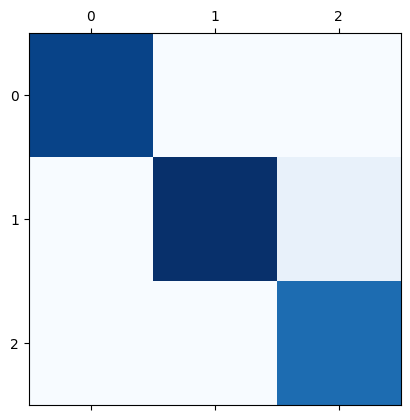

In [18]:
plt.matshow(confusion_matrix(y_test, predK), cmap=plt.cm.Blues)

Видно что модель немного ошиблась с определением 2 перепутав его с 3

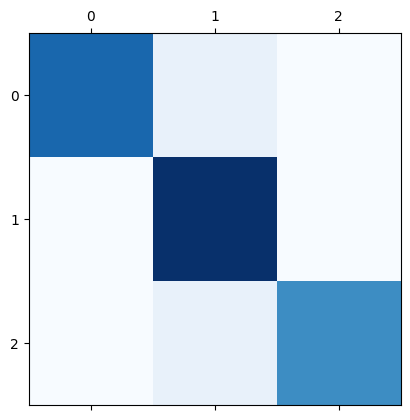

In [19]:
plt.matshow(confusion_matrix(y_test, predT), cmap=plt.cm.Blues)

Тут модель также немного ошиблась с определением 2 класса

In [20]:
results = pd.DataFrame({
    "Модель": ["Метод ближайших соседей", "Дерево решений"],
    "Accuracy": [accK, accT],
})
results

,Модель,Accuracy
0,Метод ближайших соседей,0.972222
1,Дерево решений,0.944444


По матрицам ошибок и метрике accuracy лучше выглядит метод ближайших соседей: у него меньше ошибок классификации, хотя разница небольшая. Масштабирование признаков важно для метода ближайших соседей, потому что он сравнивает объекты по расстояниям, и признаки с большими числовыми значениями иначе могут сильнее влиять на результат. Однако по одной небольшой тестовой выборке нельзя уверенно заключить, что метод соседей всегда лучше решающего дерева. Для более надёжного сравнения следует оценить обе модели на нескольких разбиениях

In [22]:
modelK3 = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))])

modelK7 = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=7))])


In [24]:
predK3 = modelK3.fit(X_train, y_train).predict(X_test)
predK7 = modelK7.fit(X_train, y_train).predict(X_test)

In [25]:
print(f'k = 3: {accuracy_score(y_test, predK3)}\nk = 5: {accuracy_score(y_test, predK)}\nk = 7: {accuracy_score(y_test, predK7)}')

k = 3: 0.9722222222222222
k = 5: 0.9722222222222222
k = 7: 1.0


При k = 3 модель показала же такую же метрику accuracy как и при k = 5, модель с k = 7 показала наилучший результат не совершив ни одной ошибки